# Tugas Logistic Regression — Prediksi Obesitas (4a & 4b)

**Dataset:** `ObesityDataSet_raw_and_data_sinthetic.csv`  
**Kelas yang dipakai:** `Non_Obese` (0) vs `Obese` (1)
- **Kelas 0 (`Non_Obese`):** `Insufficient_Weight`, `Normal_Weight`, `Overweight_Level_I`, `Overweight_Level_II`
- **Kelas 1 (`Obese`):** `Obesity_Type_I`, `Obesity_Type_II`, `Obesity_Type_III`

## Pilihan implementasi

| Bagian | Data | Fitur | Implementasi |
|---|---|---|---|
| **4a** | 5 data latih + 1 data uji | 2 fitur (`Age`, `FAF`) | **Manual NumPy** — sigmoid, binary cross-entropy, gradient descent, ditampilkan per langkah selama 2 epoch. Sampel latih (baris 59, 0, 3, 10, 202) dan uji (baris 68) selaras dengan representasi pada dokumen laporan. |
| **4b** | Seluruh data (2.084 data setelah deduplikasi), split 80:20 | Seluruh fitur non-leakage (14 fitur mentah -> 16 fitur hasil encoding) | **scikit-learn `LogisticRegression`** + pembanding **manual NumPy (gradient descent)** |

**Alasan pengelompokan kelas:**
Menggabungkan kategori menjadi biner (`Non_Obese` vs `Obese`) mencerminkan kebutuhan deteksi klinis nyata (apakah seseorang tergolong obesitas atau tidak). Seluruh data dari dataset tetap terpakai secara proporsional tanpa harus membuang 5 kategori lainnya.

**Catatan leakage:** `Weight` dan `Height` dibuang karena label obesitas diturunkan langsung dari rumus BMI ($W/H^2$). Jika kedua kolom tersebut dipakai, model akan mengalami *target leakage* dan akurasi semu (~99%), sehingga tidak menguji pengaruh pola makan, gaya hidup, atau riwayat keluarga.

## 1. Import library dan konfigurasi

In [1]:
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

ROOT = Path.cwd()
if not (ROOT / "data" / "raw").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "raw" / "ObesityDataSet_raw_and_data_sinthetic.csv"
OUTPUT_DIR = ROOT / "output"
OUTPUT_DIR.mkdir(exist_ok=True)

print("ROOT      :", ROOT)
print("DATA_PATH :", DATA_PATH)
print("OUTPUT_DIR:", OUTPUT_DIR)

ROOT      : C:\syntax\kuliah\matkul\ml\ob - linear logistik
DATA_PATH : C:\syntax\kuliah\matkul\ml\ob - linear logistik\data\raw\ObesityDataSet_raw_and_data_sinthetic.csv
OUTPUT_DIR: C:\syntax\kuliah\matkul\ml\ob - linear logistik\output


## 2. Load dataset dan inspeksi awal

In [2]:
raw = pd.read_csv(DATA_PATH)

print("Shape:", raw.shape)
display(raw.head())
raw.info()
print("Jumlah missing value:", int(raw.isna().sum().sum()))
print("Jumlah baris duplikat:", int(raw.duplicated().sum()))
print("\nDistribusi label asli:")
display(raw["NObeyesdad"].value_counts().to_frame("jumlah"))

Shape: (2111, 17)


,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.0,Female,1.62,64.0,no,no,2.0,3.0,no,no,2.0,yes,0.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1,21.0,Female,1.52,56.0,Sometimes,no,3.0,3.0,yes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,23.0,Male,1.80,77.0,Frequently,no,2.0,3.0,no,no,2.0,yes,2.0,1.0,Sometimes,Public_Transportation,Normal_Weight
3,27.0,Male,1.80,87.0,Frequently,no,3.0,3.0,no,no,2.0,no,2.0,0.0,Sometimes,Walking,Overweight_Level_I
4,22.0,Male,1.78,89.8,Sometimes,no,2.0,1.0,no,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2111 non-null   object 
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  family_history_with_overweight  2111 non-null   object 
 12  FAF                             21

,jumlah
NObeyesdad,
Obesity_Type_I,351
Obesity_Type_III,324
Obesity_Type_II,297
Overweight_Level_I,290
Overweight_Level_II,290
Normal_Weight,287
Insufficient_Weight,272


## 3. Pra-pemrosesan data

Tahapan yang dilakukan:

1. Menyeragamkan nama kolom dan mengganti nama target menjadi `Obesity_Level`.
2. Membersihkan spasi dan kapitalisasi teks kategori.
3. Membulatkan kolom survei/usia yang memiliki nilai desimal artifisial dari data sintetis.
4. Menghapus duplikat.
5. Mengelompokkan 7 level menjadi target biner: `Non_Obese` (0) vs `Obese` (1).
6. Membuang `Weight` dan `Height` untuk mencegah *leakage*.

In [3]:
df = raw.copy()
df.columns = [col.strip() for col in df.columns]
df = df.rename(columns={"NObeyesdad": "Obesity_Level"})

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype(str).str.strip()

for col in ["FAVC", "SCC", "SMOKE", "family_history_with_overweight"]:
    df[col] = df[col].str.lower().map({"yes": "Yes", "no": "No"})

for col in ["CALC", "CAEC"]:
    df[col] = df[col].str.lower().map(
        {
            "no": "No",
            "sometimes": "Sometimes",
            "frequently": "Frequently",
            "always": "Always",
        }
    )

df["Gender"] = df["Gender"].str.title()
df["MTRANS"] = df["MTRANS"].str.strip()

survey_cols = ["Age", "FCVC", "NCP", "CH2O", "FAF", "TUE"]
df[survey_cols] = df[survey_cols].round().astype(int)
df = df.drop_duplicates().reset_index(drop=True)

print("Shape setelah cleaning + drop duplicate:", df.shape)
print("Missing value setelah cleaning:", int(df.isna().sum().sum()))
print("\nNilai kategori setelah standardisasi:")
for col in ["Gender", "FAVC", "SCC", "SMOKE", "family_history_with_overweight", "CALC", "CAEC", "MTRANS"]:
    print(f"{col:35s}: {sorted(df[col].unique())}")

Shape setelah cleaning + drop duplicate: (2084, 17)
Missing value setelah cleaning: 0

Nilai kategori setelah standardisasi:
Gender                             : ['Female', 'Male']
FAVC                               : ['No', 'Yes']
SCC                                : ['No', 'Yes']
SMOKE                              : ['No', 'Yes']
family_history_with_overweight     : ['No', 'Yes']
CALC                               : ['Always', 'Frequently', 'No', 'Sometimes']
CAEC                               : ['Always', 'Frequently', 'No', 'Sometimes']
MTRANS                             : ['Automobile', 'Bike', 'Motorbike', 'Public_Transportation', 'Walking']


### 3.1 Mengelompokkan kelas menjadi target biner (Non-Obese vs Obese)

Pengelompokan 7 kategori:
- **Kelas 0 (`Non_Obese`):** `Insufficient_Weight`, `Normal_Weight`, `Overweight_Level_I`, `Overweight_Level_II`
- **Kelas 1 (`Obese`):** `Obesity_Type_I`, `Obesity_Type_II`, `Obesity_Type_III`

Shape data setelah pengelompokan: (2084, 17)

Distribusi sub-kategori asli pada setiap kelas target:


jumlah
Target_Label Obesity_Level              
Non_Obese    Insufficient_Weight     266
             Normal_Weight           282
             Overweight_Level_I      276
             Overweight_Level_II     288
Obese        Obesity_Type_I          351
             Obesity_Type_II         297
             Obesity_Type_III        324


Distribusi kelas biner:


,jumlah
Target_Label,
Non_Obese,1112
Obese,972


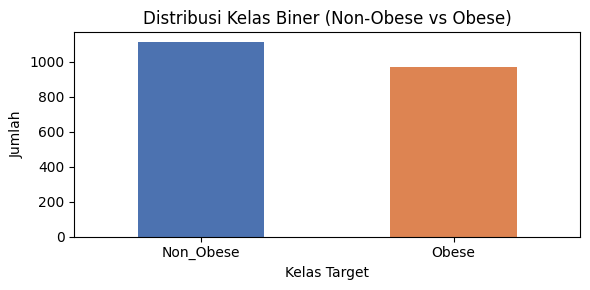

In [4]:
NON_OBESE_CLASSES = [
    "Insufficient_Weight",
    "Normal_Weight",
    "Overweight_Level_I",
    "Overweight_Level_II",
]
OBESE_CLASSES = [
    "Obesity_Type_I",
    "Obesity_Type_II",
    "Obesity_Type_III",
]

CLASS_0 = "Non_Obese"
CLASS_1 = "Obese"

df["target"] = df["Obesity_Level"].apply(lambda x: 1 if x in OBESE_CLASSES else 0)
df["Target_Label"] = df["target"].map({0: CLASS_0, 1: CLASS_1})
df_bin = df.drop(columns=["Weight", "Height"]).reset_index(drop=True)

print("Shape data setelah pengelompokan:", df_bin.shape)
print("\nDistribusi sub-kategori asli pada setiap kelas target:")
display(df.groupby(["Target_Label", "Obesity_Level"]).size().to_frame("jumlah"))

print("\nDistribusi kelas biner:")
display(df_bin["Target_Label"].value_counts().to_frame("jumlah"))

counts = df_bin["Target_Label"].value_counts()
ax = counts.plot(kind="bar", color=["#4C72B0", "#DD8452"], figsize=(6, 3))
ax.set_title("Distribusi Kelas Biner (Non-Obese vs Obese)")
ax.set_xlabel("Kelas Target")
ax.set_ylabel("Jumlah")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Bagian 4a — 5 data latih + 1 data uji

Bagian 4a mengikuti format materi/slide (2 fitur: `Age` dan `FAF`) agar perhitungan manual langkah-demi-langkah transparan dan mudah dipahami.
Sampel yang dipilih identik dengan data pada dokumen laporan:
- **5 data latih:** Baris 59 (`Insufficient_Weight`, kelas 0), Baris 0 (`Normal_Weight`, kelas 0), Baris 3 (`Overweight_Level_I`, kelas 0), Baris 10 (`Obesity_Type_I`, kelas 1), Baris 202 (`Obesity_Type_III`, kelas 1).
- **1 data uji:** Baris 68 (`Obesity_Type_II`, kelas 1).

In [5]:
train_idx_raw = [59, 0, 3, 10, 202]
test_idx_raw = [68]

train_4a = raw.iloc[train_idx_raw].copy().reset_index(drop=True)
test_4a = raw.iloc[test_idx_raw].copy().reset_index(drop=True)

for dset in [train_4a, test_4a]:
    dset["target"] = dset["NObeyesdad"].apply(lambda x: 1 if x in OBESE_CLASSES else 0)
    dset["Target_Label"] = dset["target"].map({0: CLASS_0, 1: CLASS_1})
    dset["Age"] = dset["Age"].round().astype(int)
    dset["FAF"] = dset["FAF"].round().astype(int)

print("5 data latih:")
display(train_4a[["Age", "Gender", "FAF", "NObeyesdad", "Target_Label", "target"]])
print("1 data uji:")
display(test_4a[["Age", "Gender", "FAF", "NObeyesdad", "Target_Label", "target"]])

5 data latih:


,Age,Gender,FAF,NObeyesdad,Target_Label,target
0,20,Male,2,Insufficient_Weight,Non_Obese,0
1,21,Female,0,Normal_Weight,Non_Obese,0
2,27,Male,2,Overweight_Level_I,Non_Obese,0
3,26,Male,2,Obesity_Type_I,Obese,1
4,26,Female,0,Obesity_Type_III,Obese,1


1 data uji:


,Age,Gender,FAF,NObeyesdad,Target_Label,target
0,30,Male,0,Obesity_Type_II,Obese,1


### 4.1 Standarisasi fitur 4a

`StandardScaler` di-*fit* hanya pada 5 data latih, lalu dipakai untuk mentransformasi data uji. Tujuannya agar data uji tidak memengaruhi parameter pra-pemrosesan.

In [6]:
FEATURES_4A = ["Age", "FAF"]

scaler_4a = StandardScaler()
X_train_4a = scaler_4a.fit_transform(train_4a[FEATURES_4A])
X_test_4a = scaler_4a.transform(test_4a[FEATURES_4A])
y_train_4a = train_4a["target"].to_numpy()
y_test_4a = test_4a["target"].to_numpy()

print("Mean data latih :", dict(zip(FEATURES_4A, scaler_4a.mean_)))
print("Std data latih  :", dict(zip(FEATURES_4A, scaler_4a.scale_)))

display(
    pd.DataFrame(X_train_4a, columns=["x1_Age_std", "x2_FAF_std"]).assign(
        y=y_train_4a
    )
)

Mean data latih : {'Age': 24.0, 'FAF': 1.2}
Std data latih  : {'Age': 2.898275349237888, 'FAF': 0.9797958971132713}


,x1_Age_std,x2_FAF_std,y
0,-1.380131,0.816497,0
1,-1.035098,-1.224745,0
2,1.035098,0.816497,0
3,0.690066,0.816497,1
4,0.690066,-1.224745,1


### 4.2 Langkah per langkah selama 2 epoch

Rumus yang dipakai:

$$z = x_1w_1 + x_2w_2 + b$$

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

$$L = -\left[y\log(\sigma) + (1-y)\log(1-\sigma)\right]$$

$$J = \frac{1}{n}\sum L$$

$$w_j \leftarrow w_j - \alpha \cdot \frac{1}{n}\sum(\sigma - y)x_j$$

$$b \leftarrow b - \alpha \cdot \frac{1}{n}\sum(\sigma - y)$$

In [7]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


def train_logreg_manual(X, y, learning_rate=1.0, epochs=2, verbose=True):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    b = 0.0
    history = []

    for epoch in range(1, epochs + 1):
        z = X @ w + b
        y_hat = sigmoid(z)
        eps = 1e-12
        loss = -(y * np.log(y_hat + eps) + (1 - y) * np.log(1 - y_hat + eps))
        error = y_hat - y
        dw = (X.T @ error) / n_samples
        db = error.mean()

        if verbose:
            table = pd.DataFrame(
                {
                    "data": np.arange(1, n_samples + 1),
                    "x1": X[:, 0],
                    "x2": X[:, 1],
                    "z": z,
                    "sigma": y_hat,
                    "y": y,
                    "L": loss,
                    "(sigma-y)": error,
                    "(sigma-y)*x1": error * X[:, 0],
                    "(sigma-y)*x2": error * X[:, 1],
                }
            )
            summary = pd.DataFrame(
                {
                    "Total L": [loss.sum()],
                    "J = mean(L)": [loss.mean()],
                    "sum((sigma-y)*x1)": [(error * X[:, 0]).sum()],
                    "sum((sigma-y)*x2)": [(error * X[:, 1]).sum()],
                    "db = mean(sigma-y)": [db],
                    "dw1 = sum(...)/n": [dw[0]],
                    "dw2 = sum(...)/n": [dw[1]],
                }
            )
            print(f"Epoch {epoch} — sebelum update")
            display(table.round(6))
            display(summary.round(6))

        history.append(
            {
                "epoch": epoch,
                "loss": loss.mean(),
                "w1": w[0],
                "w2": w[1],
                "b": b,
                "dw1": dw[0],
                "dw2": dw[1],
                "db": db,
            }
        )

        w = w - learning_rate * dw
        b = b - learning_rate * db

        if verbose:
            print(f"Update -> w1={w[0]:.6f}, w2={w[1]:.6f}, b={b:.6f}\n")

    return w, b, pd.DataFrame(history)


w_4a, b_4a, history_4a = train_logreg_manual(
    X_train_4a,
    y_train_4a,
    learning_rate=1.0,
    epochs=2,
    verbose=True,
)
print("Bobot akhir 4a:", w_4a)
print("Bias akhir 4a :", b_4a)
display(history_4a.round(6))

Epoch 1 — sebelum update


,data,x1,x2,z,sigma,y,L,(sigma-y),(sigma-y)*x1,(sigma-y)*x2
0,1,-1.380131,0.816497,0.0,0.5,0,0.693147,0.5,-0.690066,0.408248
1,2,-1.035098,-1.224745,0.0,0.5,0,0.693147,0.5,-0.517549,-0.612372
2,3,1.035098,0.816497,0.0,0.5,0,0.693147,0.5,0.517549,0.408248
3,4,0.690066,0.816497,0.0,0.5,1,0.693147,-0.5,-0.345033,-0.408248
4,5,0.690066,-1.224745,0.0,0.5,1,0.693147,-0.5,-0.345033,0.612372


,Total L,J = mean(L),sum((sigma-y)*x1),sum((sigma-y)*x2),db = mean(sigma-y),dw1 = sum(...)/n,dw2 = sum(...)/n
0,3.465736,0.693147,-1.380131,0.408248,0.1,-0.276026,0.08165


Update -> w1=0.276026, w2=-0.081650, b=-0.100000

Epoch 2 — sebelum update


,data,x1,x2,z,sigma,y,L,(sigma-y),(sigma-y)*x1,(sigma-y)*x2
0,1,-1.380131,0.816497,-0.547619,0.366417,0,0.456364,0.366417,-0.505703,0.299178
1,2,-1.035098,-1.224745,-0.285714,0.429053,0,0.560460,0.429053,-0.444112,-0.525481
2,3,1.035098,0.816497,0.119048,0.529727,0,0.754441,0.529727,0.548319,0.432520
3,4,0.690066,0.816497,0.023810,0.505952,1,0.681313,-0.494048,-0.340925,-0.403388
4,5,0.690066,-1.224745,0.190476,0.547476,1,0.602437,-0.452524,-0.312272,0.554227


,Total L,J = mean(L),sum((sigma-y)*x1),sum((sigma-y)*x2),db = mean(sigma-y),dw1 = sum(...)/n,dw2 = sum(...)/n
0,3.055016,0.611003,-1.054694,0.357056,0.075725,-0.210939,0.071411


Update -> w1=0.486965, w2=-0.153061, b=-0.175725

Bobot akhir 4a: [ 0.48696494 -0.15306084]
Bias akhir 4a : -0.1757249774465311


,epoch,loss,w1,w2,b,dw1,dw2,db
0,1,0.693147,0.000000,0.00000,0.0,-0.276026,0.081650,0.100000
1,2,0.611003,0.276026,-0.08165,-0.1,-0.210939,0.071411,0.075725


### 4.3 Klasifikasi data uji 4a

In [8]:
z_test_4a = X_test_4a @ w_4a + b_4a
prob_test_4a = sigmoid(z_test_4a)[0]
pred_test_4a = int(prob_test_4a >= 0.5)

actual_label = CLASS_1 if y_test_4a[0] == 1 else CLASS_0
predicted_label = CLASS_1 if pred_test_4a == 1 else CLASS_0

result_4a = pd.DataFrame(
    {
        "Age": test_4a["Age"].to_numpy(),
        "FAF": test_4a["FAF"].to_numpy(),
        "Sub-level Asli": test_4a["NObeyesdad"].to_numpy(),
        "Aktual": [actual_label],
        "Probabilitas kelas 1": [prob_test_4a],
        "Prediksi": [predicted_label],
        "Benar": [pred_test_4a == y_test_4a[0]],
    }
)
display(result_4a.round(4))

,Age,FAF,Sub-level Asli,Aktual,Probabilitas kelas 1,Prediksi,Benar
0,30,0,Obesity_Type_II,Obese,0.7349,Obese,True


## 5. Bagian 4b — Semua data dengan split 80:20

Pada bagian ini seluruh 2.084 baris hasil pembersihan dataset dipakai. Pembagian data 80:20 dilakukan secara *stratified* **sebelum** encoder dan scaler di-*fit* agar tidak terjadi data leakage. Fitur `Age` juga di-*capping* berdasarkan batas IQR data latih saja.

In [9]:
FEATURES = [col for col in df_bin.columns if col not in ["Obesity_Level", "target", "Target_Label"]]
X = df_bin[FEATURES].copy()
y = df_bin["target"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

q1 = X_train["Age"].quantile(0.25)
q3 = X_train["Age"].quantile(0.75)
iqr = q3 - q1
age_upper = q3 + 1.5 * iqr

X_train = X_train.copy()
X_test = X_test.copy()
X_train["Age"] = X_train["Age"].clip(upper=age_upper)
X_test["Age"] = X_test["Age"].clip(upper=age_upper)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Batas atas Age (IQR data latih):", age_upper)
print("\nProporsi kelas data latih:")
display(y_train.value_counts(normalize=True).round(4).to_frame("proporsi"))
print("Proporsi kelas data uji:")
display(y_test.value_counts(normalize=True).round(4).to_frame("proporsi"))

Shape X_train: (1667, 14)
Shape X_test : (417, 14)
Batas atas Age (IQR data latih): 35.0

Proporsi kelas data latih:


,proporsi
target,
0,0.5333
1,0.4667


Proporsi kelas data uji:


,proporsi
target,
0,0.5348
1,0.4652


### 5.1 Preprocessing + model scikit-learn

Kolom numerik distandarisasi, kolom biner di-*one-hot*, kolom ordinal (`CALC`, `CAEC`) di-encode sesuai urutan tingkatannya, dan kolom nominal `MTRANS` di-*one-hot*.

In [10]:
numeric_features = ["Age", "FCVC", "NCP", "CH2O", "FAF", "TUE"]
binary_features = ["Gender", "FAVC", "SCC", "SMOKE", "family_history_with_overweight"]
ordinal_features = ["CALC", "CAEC"]
nominal_features = ["MTRANS"]

ordinal_categories = [["No", "Sometimes", "Frequently", "Always"]] * len(ordinal_features)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            numeric_features,
        ),
        ("bin", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), binary_features),
        (
            "ord",
            Pipeline(
                [
                    ("encoder", OrdinalEncoder(categories=ordinal_categories)),
                    ("scaler", StandardScaler()),
                ]
            ),
            ordinal_features,
        ),
        ("nom", OneHotEncoder(handle_unknown="ignore"), nominal_features),
    ],
    remainder="drop",
)

pipe = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
y_prob = pipe.predict_proba(X_test)[:, 1]

feature_names = pipe.named_steps["preprocessor"].get_feature_names_out()
print("Jumlah fitur setelah preprocessing:", len(feature_names))
for name in feature_names:
    print("-", name)

Jumlah fitur setelah preprocessing: 18
- num__Age
- num__FCVC
- num__NCP
- num__CH2O
- num__FAF
- num__TUE
- bin__Gender_Male
- bin__FAVC_Yes
- bin__SCC_Yes
- bin__SMOKE_Yes
- bin__family_history_with_overweight_Yes
- ord__CALC
- ord__CAEC
- nom__MTRANS_Automobile
- nom__MTRANS_Bike
- nom__MTRANS_Motorbike
- nom__MTRANS_Public_Transportation
- nom__MTRANS_Walking


### 5.2 Evaluasi model 4b

In [11]:
metrics_4b = pd.DataFrame(
    {
        "Metrik": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
        "Nilai": [
            accuracy_score(y_test, y_pred),
            precision_score(y_test, y_pred),
            recall_score(y_test, y_pred),
            f1_score(y_test, y_pred),
            roc_auc_score(y_test, y_prob),
        ],
    }
)
display(metrics_4b.round(4))

print(classification_report(y_test, y_pred, target_names=[CLASS_0, CLASS_1], digits=4))

,Metrik,Nilai
0,Accuracy,0.7458
1,Precision,0.6864
2,Recall,0.8351
3,F1-score,0.7535
4,ROC-AUC,0.8163


              precision    recall  f1-score   support

   Non_Obese     0.8232    0.6682    0.7376       223
       Obese     0.6864    0.8351    0.7535       194

    accuracy                         0.7458       417
   macro avg     0.7548    0.7516    0.7456       417
weighted avg     0.7596    0.7458    0.7450       417



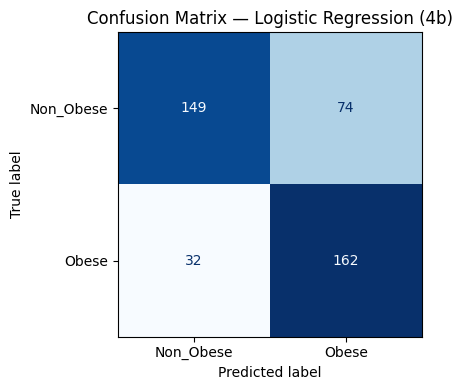

In [12]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[CLASS_0, CLASS_1]).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)
ax.set_title("Confusion Matrix — Logistic Regression (4b)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix_logreg.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Interpretasi koefisien

Koefisien positif mendorong prediksi ke arah `Obese` (kelas 1), sedangkan koefisien negatif mendorong ke arah `Non_Obese` (kelas 0). Karena fitur numerik sudah distandarisasi, besaran koefisien relatif dapat dibandingkan untuk melihat faktor paling berpengaruh.

In [14]:
coef_df = pd.DataFrame(
    {
        "Fitur": feature_names,
        "Koefisien": pipe.named_steps["classifier"].coef_[0],
    }
).sort_values("Koefisien", ascending=False)

display(coef_df.round(4))

,Fitur,Koefisien
10,bin__family_history_with_overweight_Yes,3.1850
7,bin__FAVC_Yes,2.2372
16,nom__MTRANS_Public_Transportation,0.8112
0,num__Age,0.6728
9,bin__SMOKE_Yes,0.5146
15,nom__MTRANS_Motorbike,0.4796
1,num__FCVC,0.4387
6,bin__Gender_Male,0.1182
3,num__CH2O,0.0609
11,ord__CALC,0.0603


### 5.4 Pembanding: implementasi manual NumPy pada data 80:20

Fitur hasil transformasi dari preprocessor scikit-learn dipakai untuk melatih logistic regression manual dengan gradient descent batch (2000 epoch). Ini memverifikasi bahwa implementasi pustaka konsisten dengan rumus teoritis dari materi kuliah.

In [15]:
def train_logreg_fast(X, y, learning_rate=0.5, epochs=2000):
    n_samples, n_features = X.shape
    theta = np.zeros(n_features)
    losses = []

    for _ in range(epochs):
        z = X @ theta
        y_hat = sigmoid(z)
        eps = 1e-12
        loss = -np.mean(y * np.log(y_hat + eps) + (1 - y) * np.log(1 - y_hat + eps))
        gradient = (X.T @ (y_hat - y)) / n_samples
        theta = theta - learning_rate * gradient
        losses.append(loss)

    return theta, losses


pre = pipe.named_steps["preprocessor"]
X_train_t = pre.transform(X_train)
X_test_t = pre.transform(X_test)

if hasattr(X_train_t, "toarray"):
    X_train_t = X_train_t.toarray()
    X_test_t = X_test_t.toarray()

X_train_design = np.c_[np.ones(X_train_t.shape[0]), X_train_t]
X_test_design = np.c_[np.ones(X_test_t.shape[0]), X_test_t]

theta_manual, losses = train_logreg_fast(
    X_train_design,
    y_train.to_numpy(),
    learning_rate=0.5,
    epochs=2000,
)

prob_manual = sigmoid(X_test_design @ theta_manual)
pred_manual = (prob_manual >= 0.5).astype(int)

metrics_manual = pd.DataFrame(
    {
        "Metrik": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
        "Nilai": [
            accuracy_score(y_test, pred_manual),
            precision_score(y_test, pred_manual),
            recall_score(y_test, pred_manual),
            f1_score(y_test, pred_manual),
            roc_auc_score(y_test, prob_manual),
        ],
    }
)
display(metrics_manual.round(4))

comparison = pd.DataFrame(
    {
        "Implementasi": [
            "scikit-learn LogisticRegression",
            "Manual NumPy (gradient descent)",
        ],
        "Accuracy": [
            accuracy_score(y_test, y_pred),
            accuracy_score(y_test, pred_manual),
        ],
        "F1-score": [
            f1_score(y_test, y_pred),
            f1_score(y_test, pred_manual),
        ],
        "ROC-AUC": [
            roc_auc_score(y_test, y_prob),
            roc_auc_score(y_test, prob_manual),
        ],
    }
)
display(comparison.round(4))

,Metrik,Nilai
0,Accuracy,0.7458
1,Precision,0.6864
2,Recall,0.8351
3,F1-score,0.7535
4,ROC-AUC,0.8163


,Implementasi,Accuracy,F1-score,ROC-AUC
0,scikit-learn LogisticRegression,0.7458,0.7535,0.8163
1,Manual NumPy (gradient descent),0.7458,0.7535,0.8163


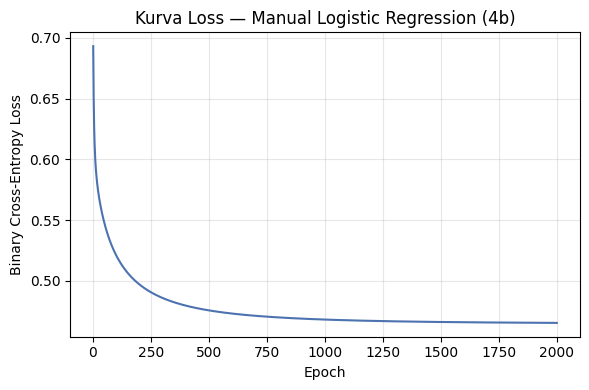

In [16]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(1, len(losses) + 1), losses, color="#4C72B0")
ax.set_xlabel("Epoch")
ax.set_ylabel("Binary Cross-Entropy Loss")
ax.set_title("Kurva Loss — Manual Logistic Regression (4b)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.5 Validasi silang 5-fold

Validasi silang dilakukan pada data latih untuk melihat kestabilan performa model di beberapa partisi data.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")

print("Akurasi per fold:", np.round(cv_scores, 4))
print(f"Rata-rata akurasi CV: {cv_scores.mean():.4f}")
print(f"Standar deviasi     : {cv_scores.std():.4f}")

Akurasi per fold: [0.8144 0.7754 0.7958 0.7417 0.7297]
Rata-rata akurasi CV: 0.7714
Standar deviasi     : 0.0319


### 5.6 Simpan model

In [18]:
model_path = OUTPUT_DIR / "logreg_obesity_model.joblib"
joblib.dump(pipe, model_path)
print("Model disimpan di:", model_path)

Model disimpan di: C:\syntax\kuliah\matkul\ml\ob - linear logistik\output\logreg_obesity_model.joblib


## 6. Kesimpulan

1. **Preprocessing & Target:** 7 kategori status berat badan dikelompokkan menjadi 2 kelas biner klinis: `Non_Obese` (0) dan `Obese` (1). Seluruh 2.084 data hasil pembersihan dapat dimanfaatkan tanpa ada kategori yang dibuang. Fitur `Weight` dan `Height` dieliminasi untuk menghindari *target leakage* dari formula BMI.
2. **Bagian 4a:** Dengan 5 data latih dan 1 data uji yang identik dengan representasi di laporan tugas, model manual 2 fitur (`Age`, `FAF`) menghasilkan pembaruan bobot yang stabil dalam 2 epoch. Data uji (`Age=30, FAF=0`) terklasifikasi sebagai `Obese` dengan probabilitas **0,7349** (prediksi benar).
3. **Bagian 4b:** Pada seluruh data (split 80:20) dengan 14 fitur non-leakage, model `LogisticRegression` scikit-learn mencapai **akurasi 74,58%**, **F1-score 75,35%**, dan **ROC-AUC 81,63%** (rata-rata validasi silang 5-fold mencapai **77,14%**).
4. **Verifikasi:** Model manual NumPy menghasilkan metrik yang identik dengan model scikit-learn pada data uji, membuktikan implementasi teoritis dan praktis telah selaras dan bebas dari kebocoran data.